In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
data = fetch_openml(name="adult", version=2, as_frame=True)

In [3]:
X = data.data
y = data.target

In [4]:
numeric_features = X.select_dtypes(include=["number"]).columns
categorical_features = X.select_dtypes(exclude=["number"]).columns

In [5]:
numeric_imputer = SimpleImputer(strategy="median")
X_numeric = numeric_imputer.fit_transform(X[numeric_features])
categorical_imputer = SimpleImputer(strategy="most_frequent")
X_categorical = categorical_imputer.fit_transform(X[categorical_features])
encoder = OneHotEncoder(handle_unknown="ignore")
X_categorical = encoder.fit_transform(X_categorical)
X = hstack([X_numeric, X_categorical]).toarray()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
model = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)

In [8]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8533114955471389

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.91      7431
        >50K       0.77      0.56      0.65      2338

    accuracy                           0.85      9769
   macro avg       0.82      0.75      0.78      9769
weighted avg       0.85      0.85      0.84      9769



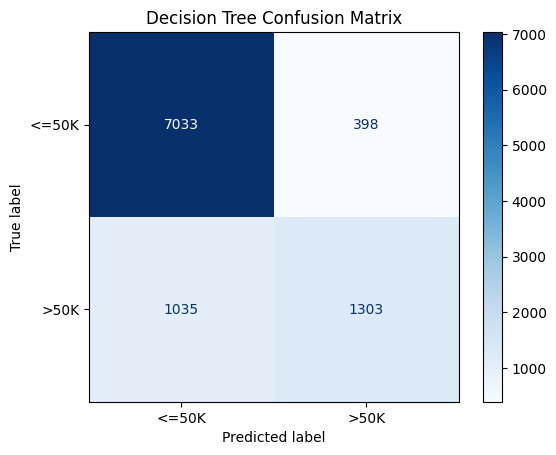

In [9]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

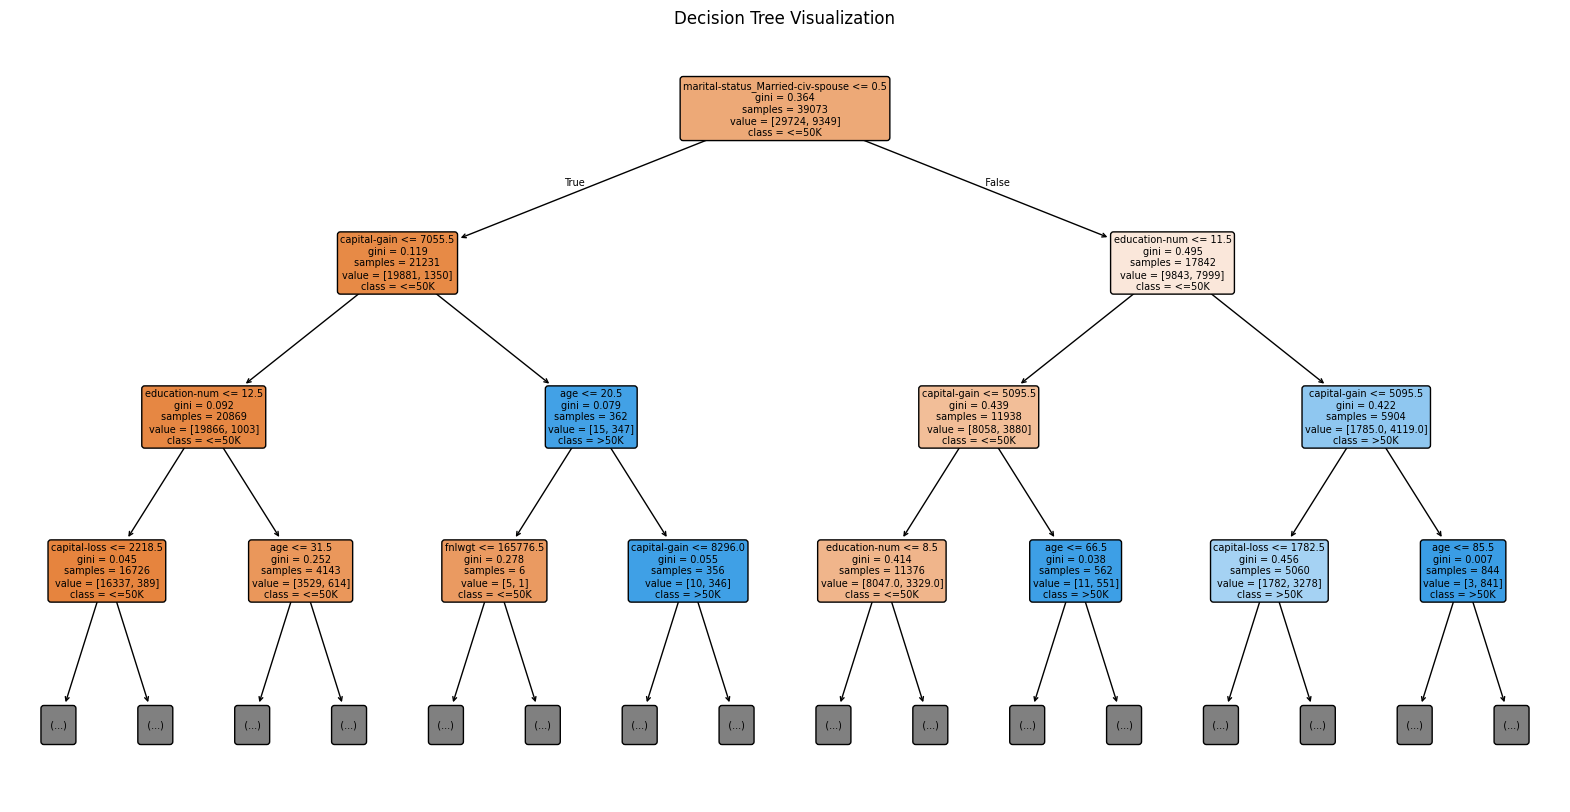

In [10]:
feature_names = (list(numeric_features) + list(encoder.get_feature_names_out(categorical_features)))
plt.figure(figsize=(20, 10))
plot_tree(model, feature_names=feature_names, class_names=[str(c) for c in model.classes_], filled=True, rounded=True, max_depth=3, fontsize=7)
plt.title("Decision Tree Visualization")
plt.show()